size: 569 raw, 30 column
1 (Benign)       357
0 (Malignant)    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


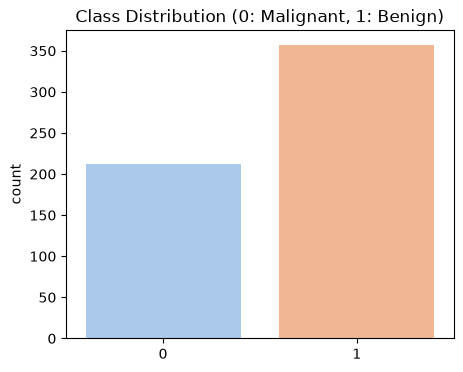


--- MISSING VALUES AND DUPLICATIONS ---
total missing values are 0
duplicated rows are 0

--- DATA TYPES ---
Number of Numerical Features: 30
Number of Categorical Features: 0

--- OUTLIERS ---
mean radius                14
mean texture                7
mean perimeter             13
mean area                  25
mean smoothness             6
mean compactness           16
mean concavity             18
mean concave points        10
mean symmetry              15
mean fractal dimension     15
radius error               38
texture error              20
perimeter error            38
area error                 65
smoothness error           30
compactness error          28
concavity error            22
concave points error       19
symmetry error             27
fractal dimension error    28
worst radius               17
worst texture               5
worst perimeter            15
worst area                 35
worst smoothness            7
worst compactness          16
worst concavity          

,mean,median,min,max,std,Q1,Q3
mean radius,14.127292,13.37000,6.98100,28.1100,3.524049,11.70000,15.7800
mean texture,19.289649,18.84000,9.71000,39.2800,4.301036,16.17000,21.8000
mean perimeter,91.969033,86.24000,43.79000,188.5000,24.298981,75.17000,104.1000
mean area,654.889104,551.10000,143.50000,2501.0000,351.914129,420.30000,782.7000
mean smoothness,0.096360,0.09587,0.05263,0.1634,0.014064,0.08637,0.1053



--- 3.2 TOP 3 STRONGEST CORRELATION PAIRS (PEARSON) ---
1. mean perimeter <---> mean radius: 0.9979
2. worst perimeter <---> worst radius: 0.9937
3. mean area <---> mean radius: 0.9874


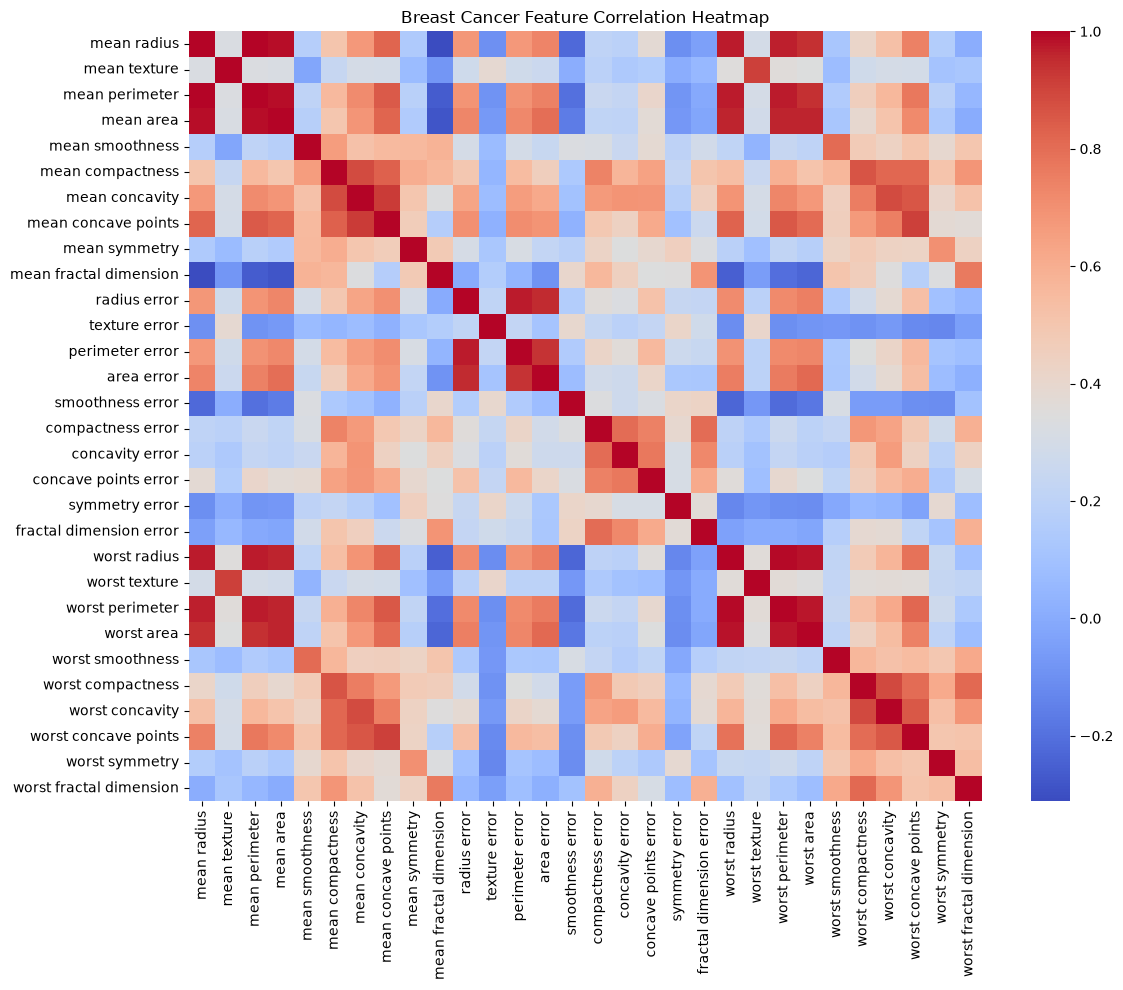


--- FEATURE DISTRIBUTIONS & OUTLIERS (BOXPLOTS) ---


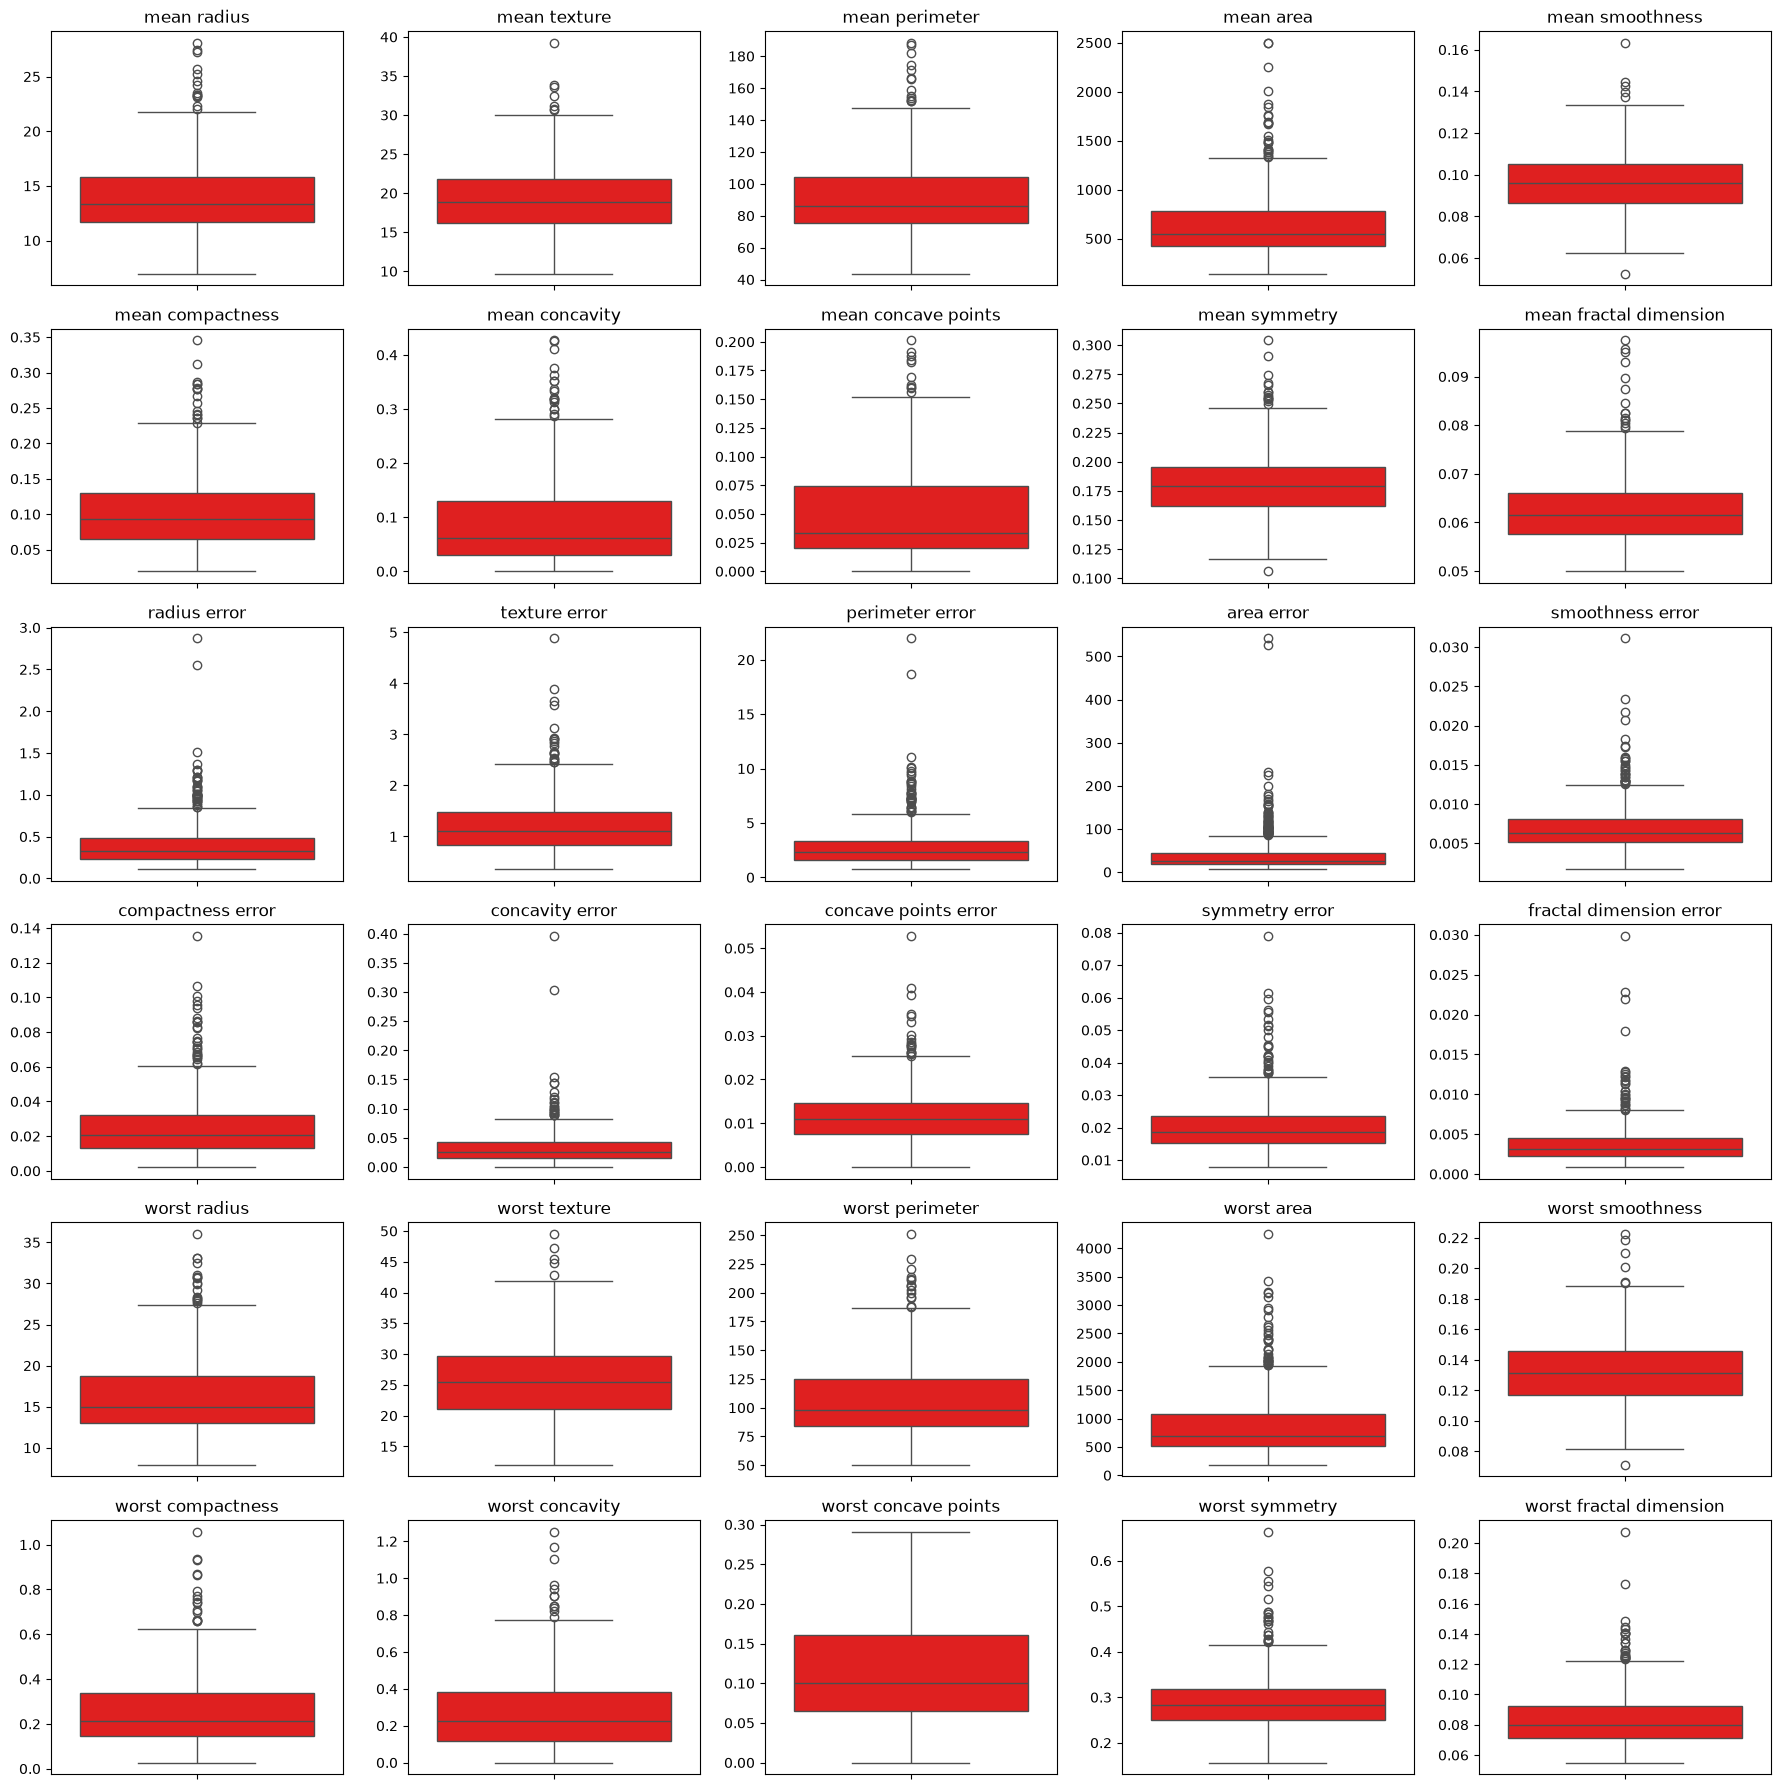

In [28]:
# ==========================================
# SECTION 1, 2 & 3: DATA LOADING, QUALITY CHECKS & EDA
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

raw_data = load_breast_cancer()

X = pd.DataFrame(raw_data.data, columns=raw_data.feature_names)
Y = raw_data.target
class_names = raw_data.target_names

print("=======================================================")
print(f"size: {X.shape[0]} raw, {X.shape[1]} column")
print(pd.Series(Y).value_counts().rename(index={0: '0 (Malignant)', 1: '1 (Benign)'}))
display(X.head())

plt.figure(figsize=(5, 4))
sns.countplot(x=Y, hue=Y, palette='pastel', legend=False)
plt.title("Class Distribution (0: Malignant, 1: Benign)")
plt.show()

missing_values = X.isnull().sum().sum()
duplicate_rows = X.duplicated().sum()

print("\n--- MISSING VALUES AND DUPLICATIONS ---")
print(f"total missing values are {missing_values}")
print(f"duplicated rows are {duplicate_rows}")

print("\n--- DATA TYPES ---")
print(f"Number of Numerical Features: {X.select_dtypes(include=['float64', 'int64']).shape[1]}")
print(f"Number of Categorical Features: {X.select_dtypes(include=['object', 'category']).shape[1]}")

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outliers = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()

print("\n--- OUTLIERS ---")
print(outliers[outliers > 0])

stats = X.describe().T[['mean', '50%', 'min', 'max', 'std', '25%', '75%']]
stats = stats.rename(columns={'50%': 'median', '25%': 'Q1', '75%': 'Q3'})

print("\n--- 3.1 DESCRIPTIVE STATISTICS (FIRST 5 FEATURES) ---")
display(stats.head())

corr_matrix = X.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
corr_unstacked = upper_tri.unstack().dropna().sort_values(ascending=False)

print("\n--- 3.2 TOP 3 STRONGEST CORRELATION PAIRS (PEARSON) ---")
for i, ((feat1, feat2), val) in enumerate(corr_unstacked.head(3).items(), 1):
    print(f"{i}. {feat1} <---> {feat2}: {val:.4f}")

plt.figure(figsize=(12, 10))
sns.heatmap(X.corr(), cmap='coolwarm', annot=False)
plt.title("Breast Cancer Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

print("\n--- FEATURE DISTRIBUTIONS & OUTLIERS (BOXPLOTS) ---")
plt.figure(figsize=(18, 18))
for i, column in enumerate(X.columns):
    plt.subplot(6, 5, i + 1)
    sns.boxplot(y=X[column], color='red')
    plt.title(column, fontsize=12)
    plt.ylabel('')
plt.tight_layout()
plt.show()

In [29]:
# ==========================================
# SECTION 4 & 5: SPLITTING AND SCALING
# ==========================================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEEDS = [42, 52, 62]

# 1. Freeze the test set once using seed 42 (20% test subset)
X_tr_val_raw, X_test_raw, Y_tr_val, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42, stratify=Y
)

processed_datasets, split_summary, test_indices = {}, [], []

# 2. Repeated train/validation splitting, summary data collection, and scaling across 3 seeds
for seed in SEEDS:
    X_tr_raw, X_v_raw, Y_tr, Y_v = train_test_split(
        X_tr_val_raw, Y_tr_val, test_size=0.125, random_state=seed, stratify=Y_tr_val
    )
    
    # 4.2 Record split summary statistics
    for name, x_sub, y_sub in [('Train', X_tr_raw, Y_tr), ('Validation', X_v_raw, Y_v), ('Test', X_test_raw, Y_test)]:
        row = {'Seed': seed, 'Subset': name, 'Rows': len(x_sub), '%': round(len(x_sub)/len(X)*100, 1)}
        row.update({f'Class {k}': v for k, v in sorted(pd.Series(y_sub).value_counts().items())})
        split_summary.append(row)
        
    test_indices.append(X_test_raw.index.to_numpy())
    
    # 5.3 Feature scaling (scaler fitted exclusively on training data)
    scaler = StandardScaler()
    X_tr_sc = pd.DataFrame(scaler.fit_transform(X_tr_raw), columns=X.columns, index=X_tr_raw.index)
    X_v_sc = pd.DataFrame(scaler.transform(X_v_raw), columns=X.columns, index=X_v_raw.index)
    
    if seed == 42:
        X_test_scaled = pd.DataFrame(scaler.transform(X_test_raw), columns=X.columns, index=X_test_raw.index)
        print("--- 5.3 SCALING EVIDENCE (Seed 42) ---")
        print("BEFORE SCALING:"); display(X_tr_raw.head())
        print("\nAFTER SCALING:"); display(X_tr_sc.head())
         
    processed_datasets[seed] = {
        'unscaled': {'X_train': X_tr_raw, 'X_val': X_v_raw, 'Y_train': Y_tr, 'Y_val': Y_v},
        'scaled':   {'X_train': X_tr_sc,  'X_val': X_v_sc,  'Y_train': Y_tr, 'Y_val': Y_v}
    }

# 3. Display Section 4.2 outputs and perform verification check
print("\n--- 4.2 SPLIT SUMMARY TABLE (9 Rows) ---")
display(pd.DataFrame(split_summary))

is_identical = np.array_equal(test_indices[0], test_indices[1]) and np.array_equal(test_indices[1], test_indices[2])
print(f"\n[VERIFICATION] Test indices identical across seeds: {is_identical}")

--- 5.3 SCALING EVIDENCE (Seed 42) ---
BEFORE SCALING:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.46,19.89,80.43,471.3,0.08451,0.10140,0.06830,0.03099,0.1781,0.06249,...,13.46,23.07,88.13,551.3,0.1050,0.2158,0.19040,0.07625,0.2685,0.07764
390,10.26,12.22,65.75,321.6,0.09996,0.07542,0.01923,0.01968,0.1800,0.06569,...,11.38,15.65,73.23,394.5,0.1343,0.1650,0.08615,0.06696,0.2937,0.07722
420,11.57,19.04,74.20,409.7,0.08546,0.07722,0.05485,0.01428,0.2031,0.06267,...,13.07,26.98,86.43,520.5,0.1249,0.1937,0.25600,0.06664,0.3035,0.08284
356,13.05,18.59,85.09,512.0,0.10820,0.13040,0.09603,0.05603,0.2035,0.06501,...,14.19,24.85,94.22,591.2,0.1343,0.2658,0.25730,0.12580,0.3113,0.08317
446,17.75,28.03,117.30,981.6,0.09997,0.13140,0.16980,0.08293,0.1713,0.05916,...,21.53,38.54,145.40,1437.0,0.1401,0.3762,0.63990,0.19700,0.2972,0.09075



AFTER SCALING:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,-0.464835,0.176821,-0.467521,-0.518737,-0.883771,-0.073305,-0.280632,-0.466742,-0.076775,-0.069315,...,-0.573411,-0.379056,-0.561075,-0.578285,-1.226438,-0.259443,-0.416465,-0.584935,-0.339632,-0.358158
390,-1.084133,-1.553003,-1.065325,-0.944480,0.250510,-0.553959,-0.868776,-0.752546,-0.009649,0.375173,...,-1.001136,-1.547363,-1.000394,-0.854885,0.069897,-0.573037,-0.892843,-0.723620,0.046080,-0.381146
420,-0.715369,-0.014881,-0.721221,-0.693926,-0.814026,-0.520657,-0.441841,-0.889004,0.806456,-0.044313,...,-0.653609,0.236588,-0.611199,-0.632617,-0.345992,-0.395869,-0.116701,-0.728397,0.196078,-0.073535
356,-0.298750,-0.116370,-0.277754,-0.402988,0.855460,0.463223,0.051734,0.166020,0.820588,0.280719,...,-0.423295,-0.098788,-0.381515,-0.507900,0.069897,0.049213,-0.110760,0.154767,0.315465,-0.055472
446,1.024295,2.012644,1.033914,0.932543,0.251244,0.481724,0.935926,0.845785,-0.317013,-0.531861,...,1.086082,2.056753,1.127502,0.984118,0.326509,0.730725,1.637560,1.217669,0.099650,0.359420



--- 4.2 SPLIT SUMMARY TABLE (9 Rows) ---


,Seed,Subset,Rows,%,Class 0,Class 1
0,42,Train,398,69.9,149,249
1,42,Validation,57,10.0,21,36
2,42,Test,114,20.0,42,72
3,52,Train,398,69.9,149,249
4,52,Validation,57,10.0,21,36
5,52,Test,114,20.0,42,72
6,62,Train,398,69.9,149,249
7,62,Validation,57,10.0,21,36
8,62,Test,114,20.0,42,72



[VERIFICATION] Test indices identical across seeds: True


In [30]:
# ==========================================
# SECTION 7 & 8.1: CLASSIFIER RUNS
# ==========================================
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import numpy as np

classifier_runs = []
fitted_models_seed42 = {}

dt_depths = [2, 3, 5, 10, None]
knn_ks = [1, 3, 5, 7, 11]
representations = ['unscaled', 'scaled']

for seed in SEEDS:
    for rep in representations:
        X_tr = processed_datasets[seed][rep]['X_train']
        Y_tr = processed_datasets[seed][rep]['Y_train']
        X_va = processed_datasets[seed][rep]['X_val']
        Y_va = processed_datasets[seed][rep]['Y_val']
        
        # Göğüs kanserinde Malignant (0) pozitif kabul edilir
        y_va_roc_target = (Y_va == 0).astype(int)
        
        # 1. Decision Tree (5 Derinlik)
        for depth in dt_depths:
            run_id = f"bc_dt_{rep}_depth{depth}_s{seed}"
            model = DecisionTreeClassifier(max_depth=depth, random_state=seed)
            model.fit(X_tr, Y_tr)
            
            tr_preds = model.predict(X_tr)
            va_preds = model.predict(X_va)
            va_probs = model.predict_proba(X_va)[:, 0] # Sınıf 0 olasılığı
            
            classifier_runs.append({
                'run_id': run_id, 'dataset': 'breast_cancer', 'seed': seed, 'algorithm': 'DecisionTree',
                'representation': rep, 'parameter': str(depth),
                'train_acc': accuracy_score(Y_tr, tr_preds),
                'train_macro_f1': f1_score(Y_tr, tr_preds, average='macro'),
                'val_acc': accuracy_score(Y_va, va_preds),
                'val_macro_prec': precision_score(Y_va, va_preds, average='macro', zero_division=0),
                'val_macro_rec': recall_score(Y_va, va_preds, average='macro', zero_division=0),
                'val_macro_f1': f1_score(Y_va, va_preds, average='macro', zero_division=0),
                'val_roc_auc': roc_auc_score(y_va_roc_target, va_probs)
            })
            if seed == 42: fitted_models_seed42[run_id] = model
            
        # 2. KNN (5 K değeri)
        for k in knn_ks:
            run_id = f"bc_knn_{rep}_k{k}_s{seed}"
            model = KNeighborsClassifier(n_neighbors=k)
            model.fit(X_tr, Y_tr)
            
            tr_preds = model.predict(X_tr)
            va_preds = model.predict(X_va)
            va_probs = model.predict_proba(X_va)[:, 0]
            
            classifier_runs.append({
                'run_id': run_id, 'dataset': 'breast_cancer', 'seed': seed, 'algorithm': 'KNN',
                'representation': rep, 'parameter': str(k),
                'train_acc': accuracy_score(Y_tr, tr_preds),
                'train_macro_f1': f1_score(Y_tr, tr_preds, average='macro'),
                'val_acc': accuracy_score(Y_va, va_preds),
                'val_macro_prec': precision_score(Y_va, va_preds, average='macro', zero_division=0),
                'val_macro_rec': recall_score(Y_va, va_preds, average='macro', zero_division=0),
                'val_macro_f1': f1_score(Y_va, va_preds, average='macro', zero_division=0),
                'val_roc_auc': roc_auc_score(y_va_roc_target, va_probs)
            })
            if seed == 42: fitted_models_seed42[run_id] = model
            
        # 3. Gaussian Naive Bayes (1 model)
        run_id = f"bc_nb_{rep}_default_s{seed}"
        model = GaussianNB()
        model.fit(X_tr, Y_tr)
        
        tr_preds = model.predict(X_tr)
        va_preds = model.predict(X_va)
        va_probs = model.predict_proba(X_va)[:, 0]
        
        classifier_runs.append({
            'run_id': run_id, 'dataset': 'breast_cancer', 'seed': seed, 'algorithm': 'GaussianNB',
            'representation': rep, 'parameter': 'default',
            'train_acc': accuracy_score(Y_tr, tr_preds),
            'train_macro_f1': f1_score(Y_tr, tr_preds, average='macro'),
            'val_acc': accuracy_score(Y_va, va_preds),
            'val_macro_prec': precision_score(Y_va, va_preds, average='macro', zero_division=0),
            'val_macro_rec': recall_score(Y_va, va_preds, average='macro', zero_division=0),
            'val_macro_f1': f1_score(Y_va, va_preds, average='macro', zero_division=0),
            'val_roc_auc': roc_auc_score(y_va_roc_target, va_probs)
        })
        if seed == 42: fitted_models_seed42[run_id] = model

df_classifier_runs = pd.DataFrame(classifier_runs)
print(f"Toplam Eğitilen Model Çalıştırması: {len(df_classifier_runs)}/66")

Toplam Eğitilen Model Çalıştırması: 66/66


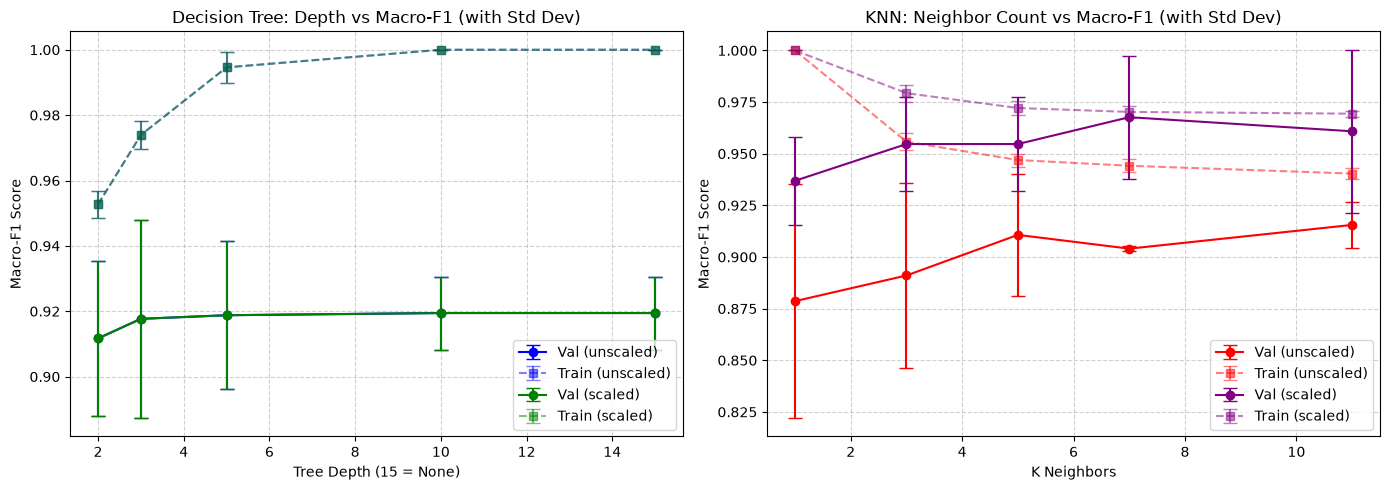

--- 9.1 CLASSIFICATION REPORT (TEST SET) ---
              precision    recall  f1-score   support

0: Malignant       1.00      0.93      0.96        42
   1: Benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

--- 9.2 MANUAL METRIC CALCULATION (CLASS 0: MALIGNANT) ---
TP: 39, FN: 3, FP: 0, TN: 72
Manual Precision: 1.0000 | Manual Recall: 0.9286 | Manual F1-Score: 0.9630


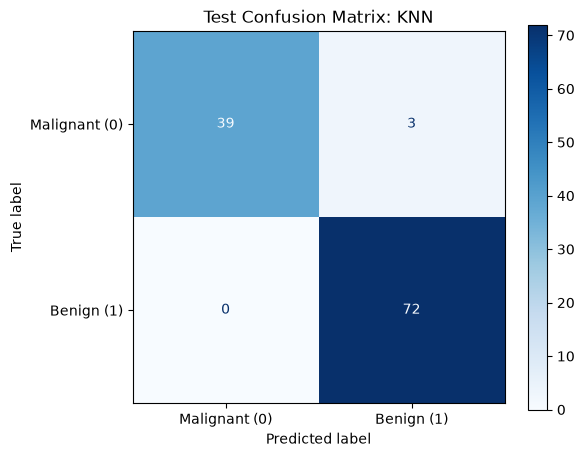

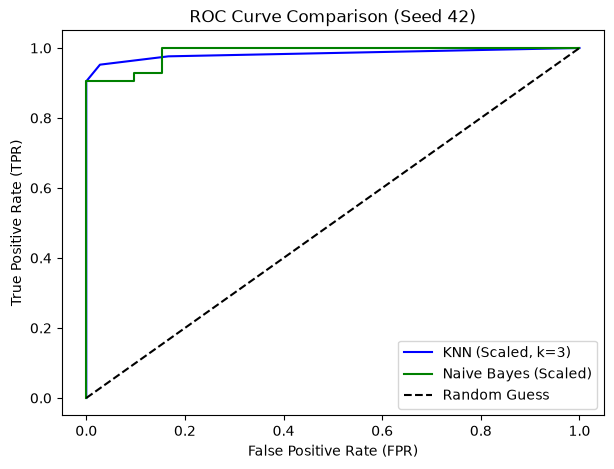

In [31]:
# ==========================================
# SECTION 8.2 & 9: EVALUATION, ERROR BARS & MANUAL METRICS
# ==========================================
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve

# --- 8.2 SUMMARY TABLE & ERROR BARS ---
df_summary = df_classifier_runs.groupby(['dataset', 'algorithm', 'representation', 'parameter']).agg(
    mean_train_macro_f1=('train_macro_f1', 'mean'),
    std_train_macro_f1=('train_macro_f1', 'std'),
    mean_val_macro_f1=('val_macro_f1', 'mean'),
    std_val_macro_f1=('val_macro_f1', 'std'),
    mean_val_acc=('val_acc', 'mean')
).reset_index().sort_values(by=['mean_val_macro_f1', 'mean_val_acc', 'std_val_macro_f1'], ascending=[False, False, True])

# Hata Çubuklu (Error Bars) Çizgi Grafikleri
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Decision Tree - Error Bar Plot (None değerlerini 15 yapıyoruz çizim için)
dt_df = df_summary[df_summary['algorithm'] == 'DecisionTree'].copy()
dt_df['x_param'] = dt_df['parameter'].apply(lambda x: 15 if x == 'None' else int(x))
dt_df = dt_df.sort_values(by='x_param')

for rep, color in zip(['unscaled', 'scaled'], ['blue', 'green']):
    sub = dt_df[dt_df['representation'] == rep]
    axes[0].errorbar(sub['x_param'], sub['mean_val_macro_f1'], yerr=sub['std_val_macro_f1'], 
                     marker='o', capsize=5, label=f'Val ({rep})', color=color)
    axes[0].errorbar(sub['x_param'], sub['mean_train_macro_f1'], yerr=sub['std_train_macro_f1'], 
                     marker='s', capsize=5, linestyle='--', label=f'Train ({rep})', color=color, alpha=0.5)

axes[0].set_title("Decision Tree: Depth vs Macro-F1 (with Std Dev)")
axes[0].set_xlabel("Tree Depth (15 = None)")
axes[0].set_ylabel("Macro-F1 Score")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# KNN - Error Bar Plot
knn_df = df_summary[df_summary['algorithm'] == 'KNN'].copy()
knn_df['x_param'] = knn_df['parameter'].astype(int)
knn_df = knn_df.sort_values(by='x_param')

for rep, color in zip(['unscaled', 'scaled'], ['red', 'purple']):
    sub = knn_df[knn_df['representation'] == rep]
    axes[1].errorbar(sub['x_param'], sub['mean_val_macro_f1'], yerr=sub['std_val_macro_f1'], 
                     marker='o', capsize=5, label=f'Val ({rep})', color=color)
    axes[1].errorbar(sub['x_param'], sub['mean_train_macro_f1'], yerr=sub['std_train_macro_f1'], 
                     marker='s', capsize=5, linestyle='--', label=f'Train ({rep})', color=color, alpha=0.5)

axes[1].set_title("KNN: Neighbor Count vs Macro-F1 (with Std Dev)")
axes[1].set_xlabel("K Neighbors")
axes[1].set_ylabel("Macro-F1 Score")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# --- 9. FINAL EVALUATION ON FIXED TEST SET ---
best_config = df_summary.iloc[0]
best_run_id = df_classifier_runs[
    (df_classifier_runs['algorithm'] == best_config['algorithm']) &
    (df_classifier_runs['representation'] == best_config['representation']) &
    (df_classifier_runs['parameter'] == best_config['parameter']) &
    (df_classifier_runs['seed'] == 42)
]['run_id'].values[0]

best_model = fitted_models_seed42[best_run_id]
X_te = X_test_scaled if best_config['representation'] == 'scaled' else X_test_raw

test_preds = best_model.predict(X_te)
test_probs = best_model.predict_proba(X_te)[:, 0] # Sınıf 0 (Malignant)

print("--- 9.1 CLASSIFICATION REPORT (TEST SET) ---")
print(classification_report(Y_test, test_preds, target_names=['0: Malignant', '1: Benign']))

cm = confusion_matrix(Y_test, test_preds)
TP = cm[0, 0]; FN = cm[0, 1]; FP = cm[1, 0]; TN = cm[1, 1]
man_precision = TP / (TP + FP) if (TP + FP) > 0 else 0
man_recall = TP / (TP + FN) if (TP + FN) > 0 else 0
man_f1 = 2 * (man_precision * man_recall) / (man_precision + man_recall) if (man_precision + man_recall) > 0 else 0

print("--- 9.2 MANUAL METRIC CALCULATION (CLASS 0: MALIGNANT) ---")
print(f"TP: {TP}, FN: {FN}, FP: {FP}, TN: {TN}")
print(f"Manual Precision: {man_precision:.4f} | Manual Recall: {man_recall:.4f} | Manual F1-Score: {man_f1:.4f}")

classifier_test = [{
    'dataset': 'breast_cancer',
    'selected_configuration': f"{best_config['algorithm']}_{best_config['representation']}_{best_config['parameter']}",
    'eval_seed': 42,
    'mean_val_macro_f1': best_config['mean_val_macro_f1'],
    'std_val_macro_f1': best_config['std_val_macro_f1'],
    'test_acc': accuracy_score(Y_test, test_preds),
    'test_macro_prec': precision_score(Y_test, test_preds, average='macro'),
    'test_macro_rec': recall_score(Y_test, test_preds, average='macro'),
    'test_macro_f1': f1_score(Y_test, test_preds, average='macro'),
    'test_roc_auc': roc_auc_score((Y_test == 0).astype(int), test_probs)
}]
df_classifier_test = pd.DataFrame(classifier_test)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=['Malignant (0)', 'Benign (1)']).plot(ax=ax, cmap='Blues')
ax.set_title(f"Test Confusion Matrix: {best_config['algorithm']}")
plt.show()

fpr_k, tpr_k, _ = roc_curve((Y_test == 0).astype(int), fitted_models_seed42[f"bc_knn_scaled_k3_s42"].predict_proba(X_test_scaled)[:,0])
fpr_n, tpr_n, _ = roc_curve((Y_test == 0).astype(int), fitted_models_seed42[f"bc_nb_scaled_default_s42"].predict_proba(X_test_scaled)[:,0])

plt.figure(figsize=(7, 5))
plt.plot(fpr_k, tpr_k, label="KNN (Scaled, k=3)", color='blue')
plt.plot(fpr_n, tpr_n, label="Naive Bayes (Scaled)", color='green')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve Comparison (Seed 42)")
plt.legend()
plt.show()


--- CONTINGENCY TABLE: K-MEANS (UNSCALED) VS TRUE CLASSES ---


Predicted Cluster,0,1
True Class,,
0,14,28
1,72,0



--- CONTINGENCY TABLE: K-MEANS (SCALED) VS TRUE CLASSES ---


Predicted Cluster,0,1
True Class,,
0,5,37
1,69,3


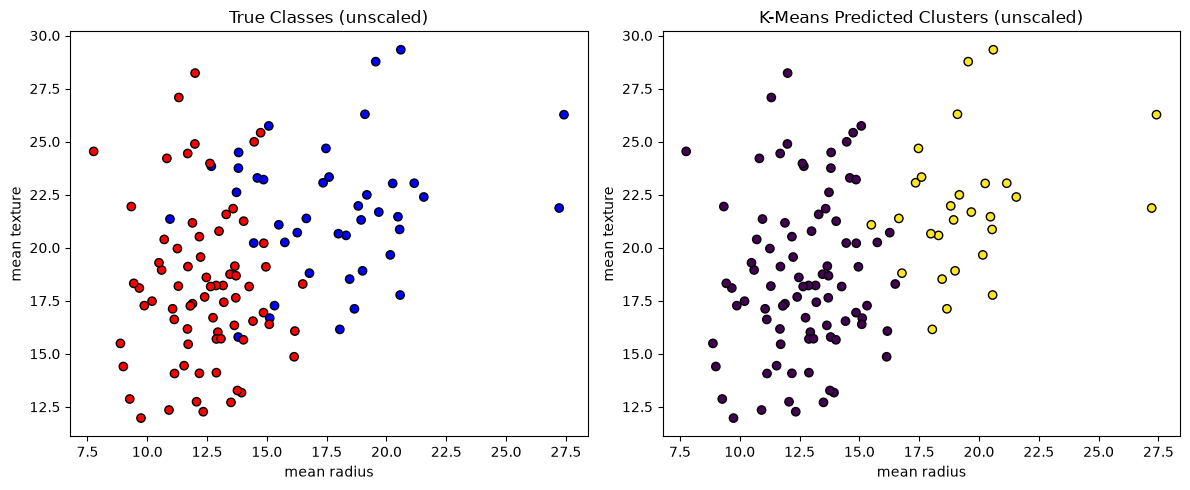

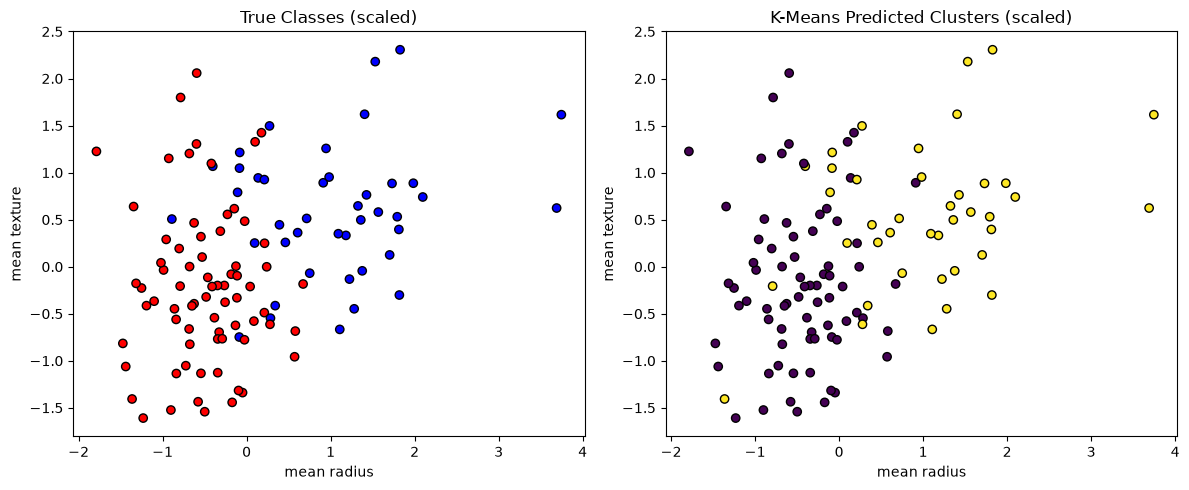

In [32]:
# ==========================================
# SECTION 10: K-MEANS CLUSTERING & VISUALIZATION
# ==========================================
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

kmeans_runs = []
kmeans_models_seed42 = {}

for seed in SEEDS:
    for rep in representations:
        X_tr = processed_datasets[seed][rep]['X_train']
        X_va = processed_datasets[seed][rep]['X_val']
        Y_va = processed_datasets[seed][rep]['Y_val']
        
        km = KMeans(n_clusters=2, random_state=seed, n_init=10)
        km.fit(X_tr)
        val_clusters = km.predict(X_va)
        
        # Silhouette sadece 1'den fazla küme oluştuğunda hesaplanabilir
        sil_score = silhouette_score(X_va, val_clusters) if len(np.unique(val_clusters)) > 1 else np.nan
        
        kmeans_runs.append({
            'dataset': 'breast_cancer', 'seed': seed, 'representation': rep,
            'inertia': km.inertia_,
            'val_ari': adjusted_rand_score(Y_va, val_clusters),
            'val_silhouette': sil_score
        })
        if seed == 42: kmeans_models_seed42[rep] = km

df_kmeans_runs = pd.DataFrame(kmeans_runs)
df_kmeans_summary = df_kmeans_runs.groupby(['dataset', 'representation']).agg(
    mean_val_ari=('val_ari', 'mean'),
    std_val_ari=('val_ari', 'std'),
    valid_score_count=('val_silhouette', 'count')
).reset_index()

# 10.2 Final Cluster Evaluation on Test Sets (Seed 42)
kmeans_test = []
for rep in representations:
    X_te = X_test_scaled if rep == 'scaled' else X_test_raw
    km_model = kmeans_models_seed42[rep]
    test_clusters = km_model.predict(X_te)
    
    # Çapraz Tablo (Contingency Table)
    print(f"\n--- CONTINGENCY TABLE: K-MEANS ({rep.upper()}) VS TRUE CLASSES ---")
    ct = pd.crosstab(Y_test, test_clusters, rownames=['True Class'], colnames=['Predicted Cluster'])
    display(ct)
    
    sil_score_test = silhouette_score(X_te, test_clusters) if len(np.unique(test_clusters)) > 1 else np.nan
    kmeans_test.append({
        'dataset': 'breast_cancer', 'representation': rep, 'eval_seed': 42,
        'cluster_0_count': sum(test_clusters == 0),
        'cluster_1_count': sum(test_clusters == 1),
        'test_ari': adjusted_rand_score(Y_test, test_clusters),
        'test_silhouette': sil_score_test
    })

df_kmeans_test = pd.DataFrame(kmeans_test)

# 10.3 Visualise Clusters (Scatter Plot: 'mean radius' vs 'mean texture')
feature_1 = 'mean radius'
feature_2 = 'mean texture'

for rep in representations:
    X_te = X_test_scaled if rep == 'scaled' else X_test_raw
    test_clusters = kmeans_models_seed42[rep].predict(X_te)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    # Gerçek Sınıflar (True Labels)
    axes[0].scatter(X_te[feature_1], X_te[feature_2], c=Y_test, cmap='bwr', edgecolor='k')
    axes[0].set_title(f"True Classes ({rep})")
    axes[0].set_xlabel(feature_1)
    axes[0].set_ylabel(feature_2)
    
    # K-Means Kümeleri (Predicted Clusters)
    axes[1].scatter(X_te[feature_1], X_te[feature_2], c=test_clusters, cmap='viridis', edgecolor='k')
    axes[1].set_title(f"K-Means Predicted Clusters ({rep})")
    axes[1].set_xlabel(feature_1)
    axes[1].set_ylabel(feature_2)
    
    plt.tight_layout()
    plt.show()

In [33]:
# ==========================================
# SECTION 12.2: EXPORT CSV FILES (BREAST CANCER)
# ==========================================
import pandas as pd
import os

DATASET_NAME = 'breast_cancer'

# Ensure kmeans_summary is explicitly created
df_km_sum = df_kmeans_runs.groupby(['dataset', 'representation']).agg(
    mean_val_ari=('val_ari', 'mean'), std_val_ari=('val_ari', 'std'), valid_score_count=('val_silhouette', 'count')
).reset_index()

# 6 ana dosyanın listesi ve hafızadaki DataFrame karşılıkları
csv_mapping = {
    'classifier_runs.csv': df_classifier_runs,
    'classifier_summary.csv': df_summary,
    'classifier_test.csv': df_classifier_test,
    'kmeans_runs.csv': df_kmeans_runs,
    'kmeans_summary.csv': df_km_sum,
    'kmeans_test.csv': df_kmeans_test
}

print(f"--- {DATASET_NAME.upper()} SONUÇLARI KAYDEDİLİYOR ---")

for filename, df_new in csv_mapping.items():
    if os.path.exists(filename):
        # Dosya varsa oku, eski breast_cancer kayıtlarını sil (çift kaydı önler), yenisini ekle
        df_existing = pd.read_csv(filename)
        if 'dataset' in df_existing.columns:
            df_existing = df_existing[df_existing['dataset'] != DATASET_NAME]
        df_combined = pd.concat([df_existing, df_new], ignore_index=True)
        df_combined.to_csv(filename, index=False)
        print(f"GÜNCELLENDİ: {filename} (Toplam satır: {len(df_combined)})")
    else:
        # Dosya yoksa direkt oluştur
        df_new.to_csv(filename, index=False)
        print(f"OLUŞTURULDU: {filename} (Toplam satır: {len(df_new)})")

--- BREAST_CANCER SONUÇLARI KAYDEDİLİYOR ---
GÜNCELLENDİ: classifier_runs.csv (Toplam satır: 132)
GÜNCELLENDİ: classifier_summary.csv (Toplam satır: 44)
GÜNCELLENDİ: classifier_test.csv (Toplam satır: 2)
GÜNCELLENDİ: kmeans_runs.csv (Toplam satır: 12)
GÜNCELLENDİ: kmeans_summary.csv (Toplam satır: 4)
GÜNCELLENDİ: kmeans_test.csv (Toplam satır: 4)
